# Classification

In [ ]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import RobustScaler

from sklearn.ensemble import HistGradientBoostingClassifier # gradient boosting
from sklearn.neural_network import MLPClassifier            # neural net
from sklearn.svm import LinearSVC                           # svm
from sklearn.linear_model import LogisticRegression         # baseline model

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

## Load dataset

In [8]:
speech_train = pd.read_csv("./speech_features_train.csv")
speech_valid = pd.read_csv("./speech_features_valid.csv")
speech_test = pd.read_csv("./speech_features_test.csv")

In [ ]:
text_train = pd.read_csv("./task1aa/text_features_train.csv").drop(columns=['transcript'],errors="ignore")
text_valid = pd.read_csv("./task1aa/text_features_valid.csv").drop(columns=['transcript'],errors="ignore")
text_test = pd.read_csv("./task1aa/text_features_test.csv").drop(columns=['transcript'],errors="ignore")

## Preprocessing

### speech-based features

In [14]:
print(len(speech_train))
print(speech_train.isnull().sum())

74111
dialog_id            0
speaker              0
da_tag               0
start_time           0
end_time             0
Min Pitch         5297
Max Pitch         5297
Mean Pitch        5297
Std Pitch         5483
Min Intensity       19
Max Intensity       19
Mean Intensity      19
Std Intensity       26
Speaking Rate       19
Jitter            5444
Shimmer           5721
HNR                418
dtype: int64


In [15]:
print(len(speech_valid))
print(speech_valid.isnull().sum())

19156
dialog_id            0
speaker              0
da_tag               0
start_time           0
end_time             0
Min Pitch         1459
Max Pitch         1459
Mean Pitch        1459
Std Pitch         1502
Min Intensity        6
Max Intensity        6
Mean Intensity       6
Std Intensity        8
Speaking Rate        6
Jitter            1496
Shimmer           1578
HNR                103
dtype: int64


In [16]:
print(len(speech_test))
print(speech_test.isnull().sum())

23540
dialog_id             0
speaker               0
da_tag            23540
start_time            0
end_time              0
Min Pitch          1751
Max Pitch          1751
Mean Pitch         1751
Std Pitch          1819
Min Intensity         7
Max Intensity         7
Mean Intensity        7
Std Intensity         7
Speaking Rate         7
Jitter             1796
Shimmer            1885
HNR                 109
dtype: int64


In [18]:
# fill missing value
def fill_missing_values(df, group_cols, features_cols):
    group_means = df.groupby(group_cols)[features_cols].transform("mean")

    df_filled = df.copy()
    df_filled[feature_cols] = df_filled[feature_cols].fillna(group_means)

    df_filled[feature_cols] = df_filled[feature_cols].fillna(df_filled[feature_cols].mean())

    return df_filled


In [ ]:
group_cols = ["dialog_id", "speaker"]

feature_cols = ['Min Pitch', 'Max Pitch', 'Mean Pitch', 'Std Pitch', 
                'Min Intensity','Max Intensity', 'Mean Intensity', 'Std Intensity', 
                'Speaking Rate', 'Jitter', 'Shimmer', 'HNR']

speech_train = fill_missing_values(speech_train, group_cols, feature_cols)
speech_valid = fill_missing_values(speech_valid, group_cols, feature_cols)
speech_test = fill_missing_values(speech_test, group_cols, feature_cols)

In [ ]:
speech_X_train = speech_train.drop(columns=['dialog_id', 'speaker', 'da_tag', 'start_time', 'end_time'])
speech_y_train = speech_train['da_tag']

speech_X_valid = speech_valid.drop(columns=['dialog_id', 'speaker', 'da_tag', 'start_time', 'end_time'])
speech_y_valid = speech_valid['da_tag']

speech_X_test = speech_test.drop(columns=['dialog_id', 'speaker', 'da_tag', 'start_time', 'end_time'])
speech_y_test = speech_test['da_tag']

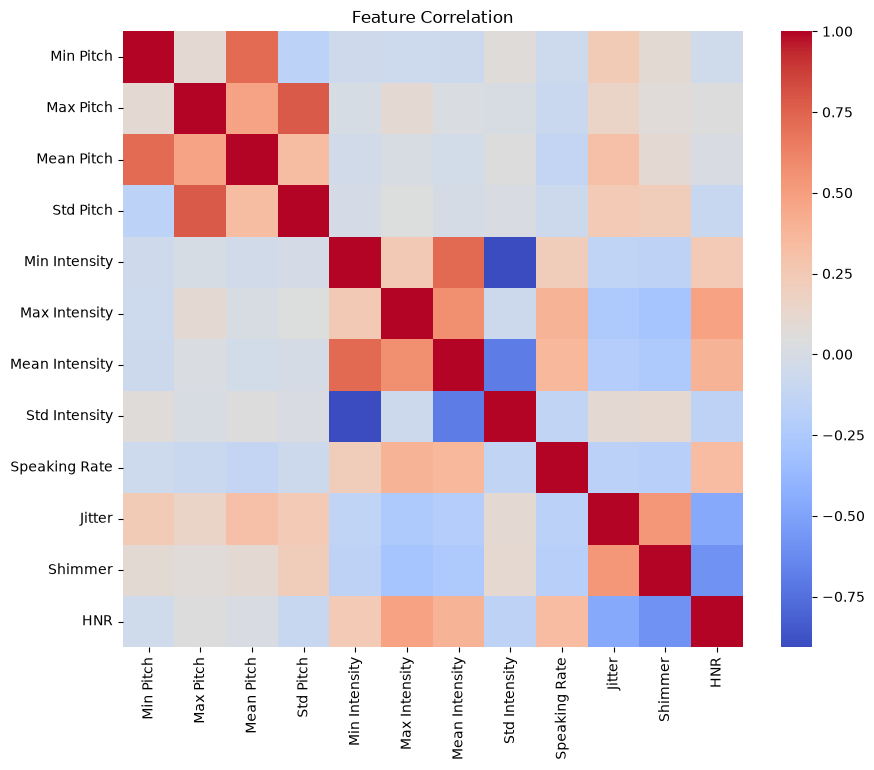

In [24]:
corr = speech_X_train.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=False, cmap="coolwarm")
plt.title("Feature Correlation")
plt.show()

In [ ]:
selected_features = ["Mean Pitch", "Mean Intensity", "Std Intensity", "Speaking Rate", "Shimmer", "Jitter"]

speech_X_train = speech_X_train[selected_features]
speech_X_valid = speech_X_valid[selected_features]
speech_X_test = speech_X_test[selected_features]

In [ ]:
robust = RobustScaler()

speech_X_train_scaled = robust.fit_transform(speech_X_train)
speech_X_valid_scaled = robust.transform(speech_X_valid)
speech_X_test_scaled = robust.transform(speech_X_test)

le = LabelEncoder()
speech_y_train = le.fit_transform(speech_y_train)
speech_y_valid = le.transform(speech_y_valid)

### text-based features

In [ ]:
text_X_train = text_train.drop(columns=['dialog_id', 'speaker', 'da_tag', 'start_time', 'end_time'])
text_y_train = text_train['da_tag']

text_X_valid = text_valid.drop(columns=['dialog_id', 'speaker', 'da_tag', 'start_time', 'end_time'])
text_y_valid = text_valid['da_tag']

text_X_test = text_test.drop(columns=['dialog_id', 'speaker', 'da_tag', 'start_time', 'end_time'])
text_y_test = text_test['da_tag']

text_X_train.describe()

,word_count,log_word_count,char_count,avg_word_length,unique_word_ratio,has_laughter,repeat_count,ends_cut,cut_count,is_sil,...,tfidf_yeah,tfidf_year,tfidf_years,tfidf_yes,tfidf_you,tfidf_you can,tfidf_you have,tfidf_you know,tfidf_you're,tfidf_your
count,74111.000000,74111.000000,74111.000000,74111.000000,74111.000000,74111.000000,74111.000000,74111.000000,74111.000000,74111.000000,...,74111.000000,74111.000000,74111.000000,74111.000000,74111.000000,74111.000000,74111.000000,74111.000000,74111.000000,74111.000000
mean,4.415768,1.081366,21.125204,2.561594,0.607991,0.021198,0.075751,0.006005,0.023883,0.337804,...,0.073367,0.002072,0.002616,0.007133,0.024637,0.001604,0.001684,0.013248,0.002417,0.002428
std,6.703030,1.069984,33.128533,2.121483,0.465372,0.144045,0.326922,0.077256,0.167680,0.472965,...,0.256822,0.031147,0.033947,0.082806,0.086891,0.026421,0.026734,0.062460,0.036709,0.034428
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.693147,5.000000,3.285714,0.909091,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,7.000000,2.079442,32.000000,4.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,74.000000,4.317488,384.000000,15.000000,1.000000,1.000000,7.000000,1.000000,5.000000,1.000000,...,1.000000,0.906717,1.000000,1.000000,1.000000,0.713128,0.765778,0.618569,1.000000,1.000000


In [ ]:
scaler = StandardScaler()

text_X_train_scaled = scaler.fit_transform(text_X_train)
text_X_valid_scaled = scaler.transform(text_X_valid)
text_X_test_scaled = scaler.transform(text_X_test)

le = LabelEncoder()
text_y_train = le.fit_transform(text_y_train)
text_y_valid = le.transform(text_y_valid)

### speech + text

In [34]:
combined_train = pd.merge(speech_train, text_train, on=["dialog_id", "speaker", "da_tag", "start_time", "end_time"])
combined_valid = pd.merge(speech_valid, text_valid, on=["dialog_id", "speaker", "da_tag", "start_time", "end_time"])
combined_test = pd.merge(speech_test, text_test, on=["dialog_id", "speaker", "da_tag", "start_time", "end_time"])

In [35]:
print(combined_train.columns)

Index(['dialog_id', 'speaker', 'da_tag', 'start_time', 'end_time', 'Min Pitch',
       'Max Pitch', 'Mean Pitch', 'Std Pitch', 'Min Intensity',
       ...
       'tfidf_yeah', 'tfidf_year', 'tfidf_years', 'tfidf_yes', 'tfidf_you',
       'tfidf_you can', 'tfidf_you have', 'tfidf_you know', 'tfidf_you're',
       'tfidf_your'],
      dtype='str', length=352)


In [ ]:
combined_X_train = combined_train.drop(columns=['dialog_id', 'speaker', 'da_tag', 'start_time', 'end_time'])
combined_y_train = combined_train['da_tag']

combined_X_valid = combined_valid.drop(columns=['dialog_id', 'speaker', 'da_tag', 'start_time', 'end_time'])
combined_y_valid = combined_valid['da_tag']

combined_X_test = combined_test.drop(columns=['dialog_id', 'speaker', 'da_tag', 'start_time', 'end_time'])
combined_y_test = combined_test['da_tag']

In [ ]:
drop_speech_columns = ['Min Pitch','Max Pitch', 'Std Pitch', 'Min Intensity','Max Intensity','HNR']

combined_X_train = combined_X_train.drop(columns=drop_speech_columns)
combined_X_valid = combined_X_valid.drop(columns=drop_speech_columns)
combined_X_test = combined_X_test.drop(columns=drop_speech_columns)

In [ ]:
from sklearn.impute import SimpleImputer

# Fill missing values using training medians
imputer = SimpleImputer(strategy="median")

combined_X_train_filled = imputer.fit_transform(combined_X_train)
combined_X_valid_filled = imputer.transform(combined_X_valid)
combined_X_test_filled = imputer.transform(combined_X_test)

robust = RobustScaler()

combined_X_train_scaled = robust.fit_transform(combined_X_train_filled)
combined_X_valid_scaled = robust.transform(combined_X_valid_filled)
combined_X_test_scaled = robust.transform(combined_X_test_filled)

In [ ]:
le = LabelEncoder()
combined_y_train = le.fit_transform(combined_y_train)
combined_y_valid = le.transform(combined_y_valid)

## Modeling

In [ ]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=1001),
    "LinearSVM": LinearSVC(max_iter=2000),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.1,
        max_leaf_nodes=31,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=15,
        class_weight="balanced",
        random_state=42
    ),
    "NeuralNet": MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=300, random_state=42)
}

In [47]:
def selectModel(models, X_train, y_train, X_valid, y_valid, feature=""):
    print(f"-- {feature} --")
    for name, model in models.items():
      print(f"{name}")
    
      model.fit(X_train, y_train)
    
      train_preds = model.predict(X_train)
      valid_preds = model.predict(X_valid)
    
      train_acc = accuracy_score(y_train, train_preds)
      valid_acc = accuracy_score(y_valid, valid_preds)
    
      train_f1 = f1_score(y_train, train_preds, average = "macro")
      valid_f1 = f1_score(y_valid, valid_preds, average = "macro")
    
      print(f" Train Acc: {train_acc:.4f}, F1: {train_f1:.4f}")
      print(f" Valid Acc: {valid_acc:.4f}, F1: {valid_f1:.4f}\n")

In [48]:
# speech-based classifier
selectModel(models, speech_X_train_scaled, speech_y_train, speech_X_valid_scaled, speech_y_valid, "Speech")

-- Speech --
LogisticRegression
 Train Acc: 0.6334, F1: 0.1967
 Valid Acc: 0.6468, F1: 0.1999

LinearSVM
 Train Acc: 0.6052, F1: 0.1597
 Valid Acc: 0.6196, F1: 0.1600

HistGradientBoosting
 Train Acc: 0.5894, F1: 0.4064
 Valid Acc: 0.5337, F1: 0.2776

NeuralNet
 Train Acc: 0.6865, F1: 0.2579
 Valid Acc: 0.6815, F1: 0.2382



/Users/devang.shah/Downloads/codes/cuCodes/fall_26/aslp/released/aslp-dar-venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
# text-based classifier
selectModel(models, text_X_train_scaled, text_y_train, text_X_valid_scaled, text_y_valid, "Text")

-- Text --
LogisticRegression
 Train Acc: 0.8444, F1: 0.6772
 Valid Acc: 0.8473, F1: 0.6777

HistGradientBoosting
 Train Acc: 0.8341, F1: 0.7290
 Valid Acc: 0.8056, F1: 0.6579

NeuralNet
 Train Acc: 0.9517, F1: 0.8657
 Valid Acc: 0.8173, F1: 0.6453



In [ ]:
# speech+text-based classifier
selectModel(models, combined_X_train_scaled, combined_y_train, combined_X_valid_scaled, combined_y_valid, "Speech+Text")

-- Speech+Text --
LogisticRegression
 Train Acc: 0.8424, F1: 0.6685
 Valid Acc: 0.8477, F1: 0.6776

HistGradientBoosting
 Train Acc: 0.8471, F1: 0.7607
 Valid Acc: 0.8105, F1: 0.6665

NeuralNet
 Train Acc: 0.9641, F1: 0.8951
 Valid Acc: 0.8176, F1: 0.6391



### best model

In [ ]:
def plot_cm(cm, title, labels):
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt=".2f" if "norm" in title.lower() else "d",
                xticklabels=labels, yticklabels=labels, cmap="Blues")
    plt.title(title)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.show()

def evaluate(best_model, X_train, y_train, X_valid, y_valid, X_test, label_encoder, feature_type):
    best_model.fit(X_train, y_train)
    valid_preds = best_model.predict(X_valid)
    test_preds = best_model.predict(X_test)

    labels_encoded = sorted(list(np.unique(y_train)))
    labels_ori = le.inverse_transform(labels_encoded)

    
    cm_raw = confusion_matrix(y_valid, valid_preds, labels=labels_encoded)
    cm_norm_true = confusion_matrix(y_valid, valid_preds, normalize="true", labels=labels_encoded)
    cm_norm_pred = confusion_matrix(y_valid, valid_preds, normalize="pred", labels=labels_encoded)
    
    plot_cm(cm_raw, f"{feature_type}-based Classifier's Confusion Matrix (Raw)", labels_ori)
    plot_cm(cm_norm_true, f"{feature_type}-based Classifier's Confusion Matrix (Normalized by True Labels)", labels_ori)
    plot_cm(cm_norm_pred, f"{feature_type}-based Classifier's Confusion Matrix (Normalized by Predicted Labels)", labels_ori)

    return valid_preds, test_preds

/Users/devang.shah/Downloads/codes/cuCodes/fall_26/aslp/released/aslp-dar-venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


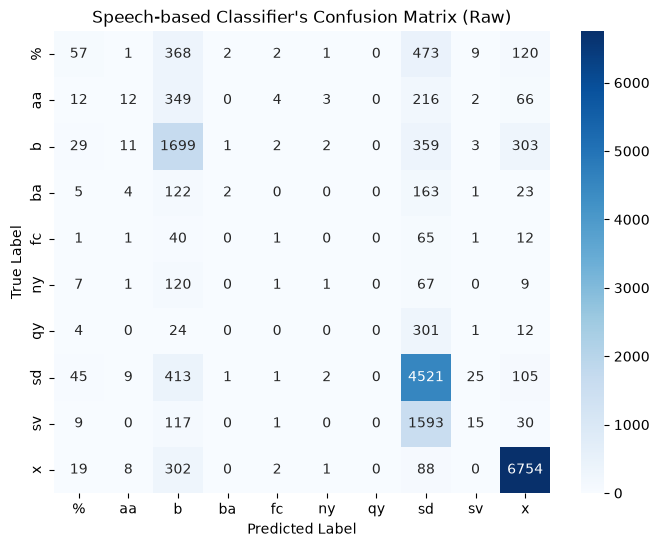

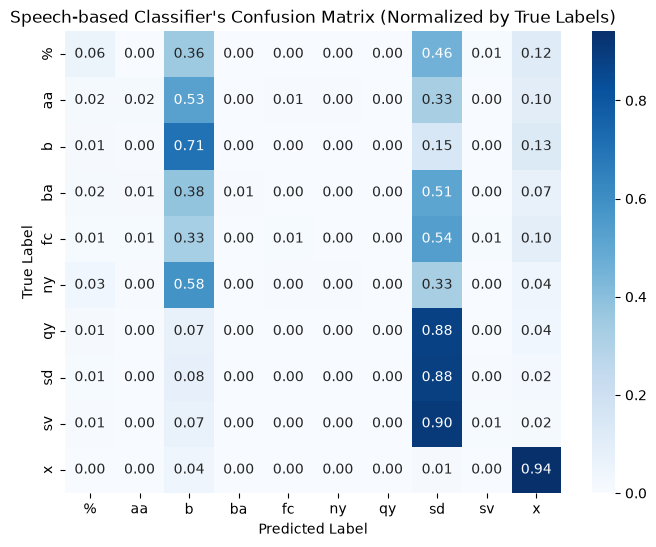

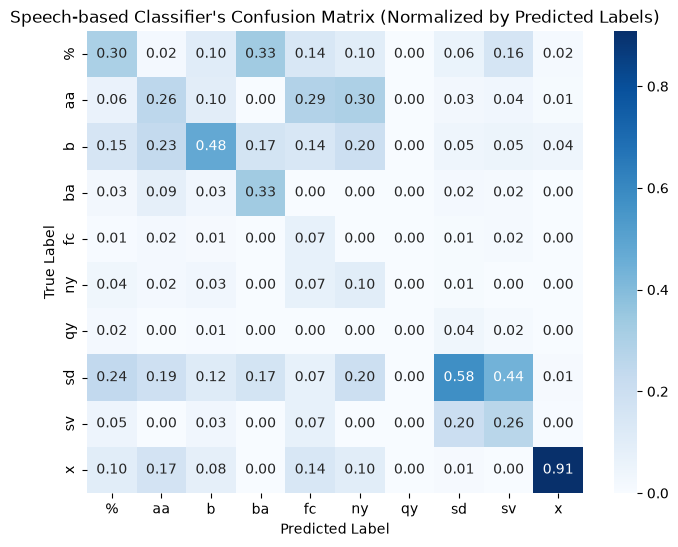

In [ ]:
best_speech_model = MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=300, random_state=42)

speech_valid_preds, speech_test_preds = evaluate(best_speech_model, speech_X_train_scaled, speech_y_train, 
                           speech_X_valid_scaled, speech_y_valid, speech_X_test_scaled, le, "Speech")

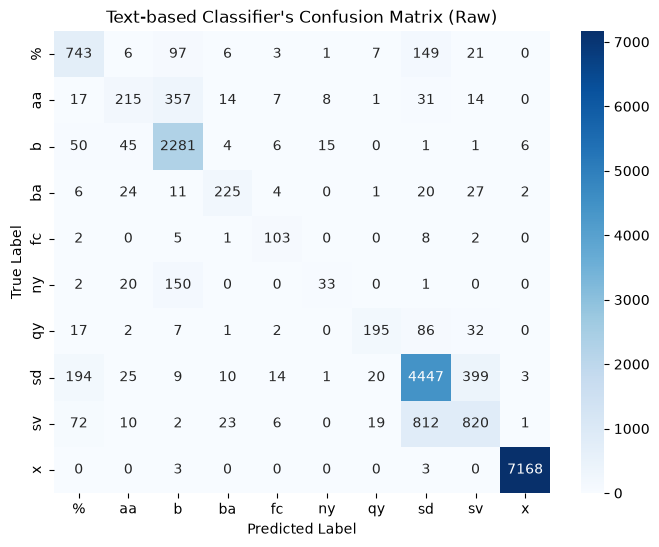

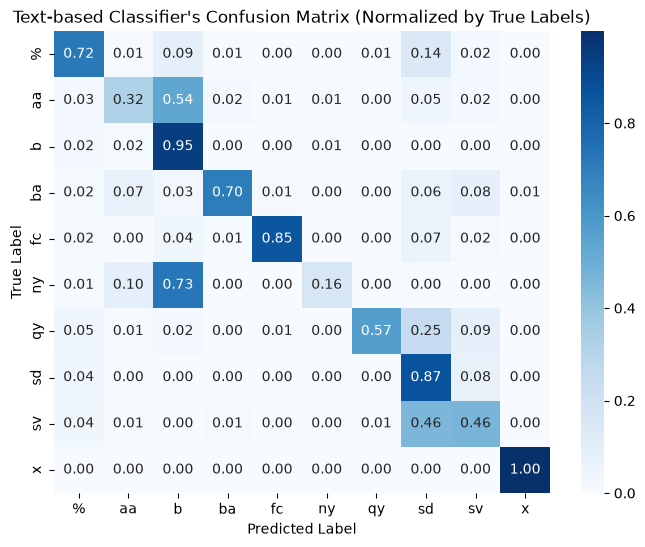

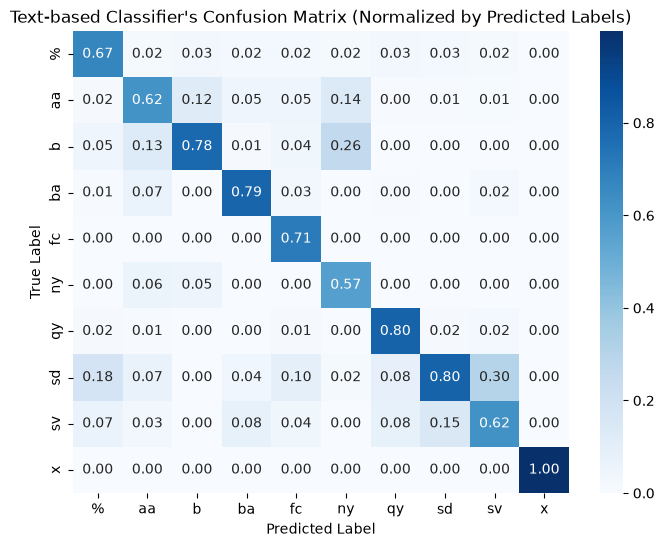

In [ ]:
best_text_model = LogisticRegression(max_iter=1001)
text_valid_preds, text_test_preds = evaluate(best_text_model, text_X_train_scaled, text_y_train, 
                           text_X_valid_scaled, text_y_valid, text_X_test_scaled, le, "Text")

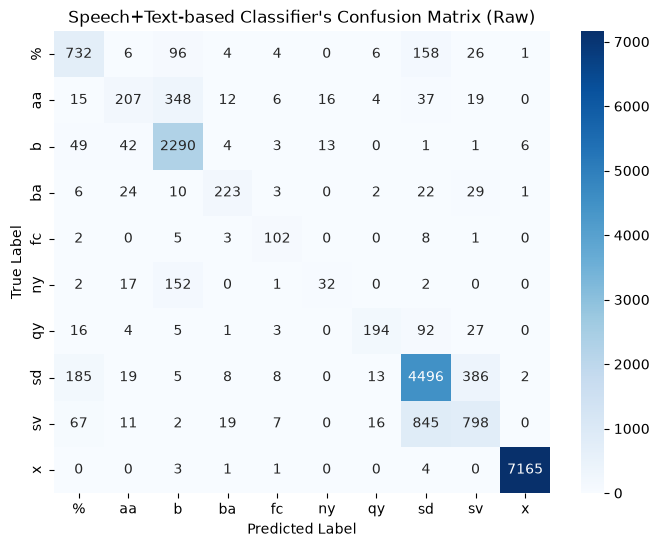

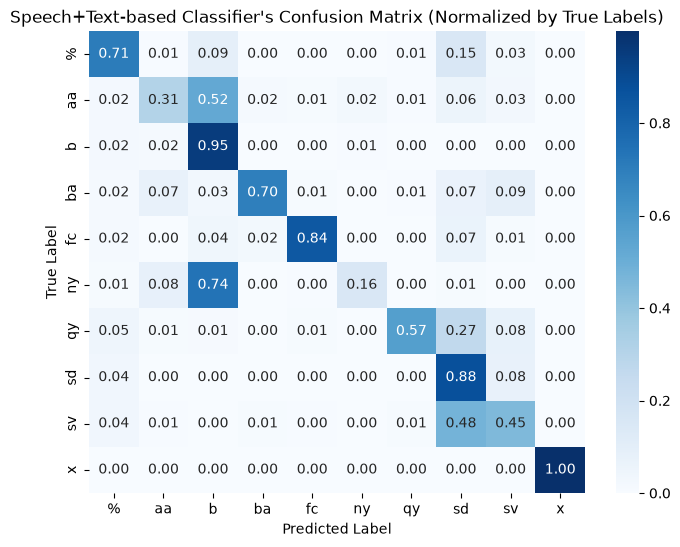

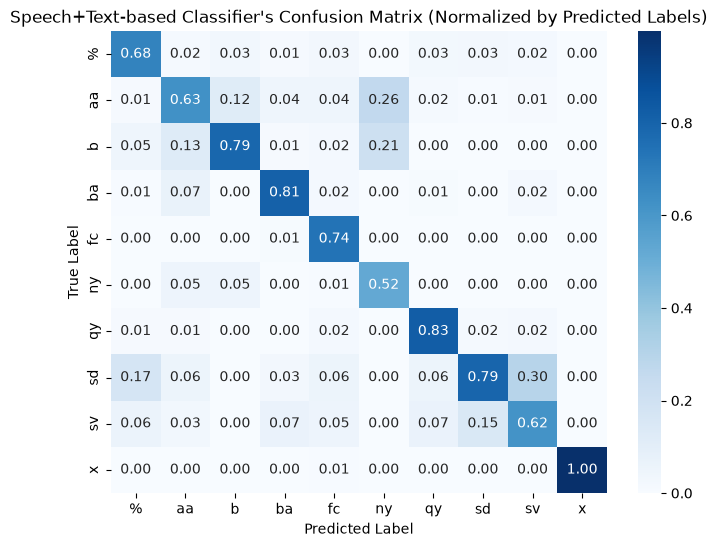

In [ ]:
best_combined_model =  LogisticRegression(max_iter=1001)
combined_valid_preds, combined_test_preds = evaluate(best_combined_model, combined_X_train_scaled, combined_y_train, 
                           combined_X_valid_scaled, combined_y_valid, combined_X_test_scaled, le, "Speech+Text")

In [ ]:
def save_submission(test_df, preds_encoded, label_encoder, output_path):
    preds_decoded = label_encoder.inverse_transform(preds_encoded)

    submission_df = test_df.copy()
    submission_df["da_tag"] = preds_decoded

    submission_df.to_csv(output_path, index=False)

save_submission(text_test, text_test_preds, le, "test_dvs2130_text1.csv")
save_submission(speech_test, speech_test_preds, le, "test_dvs2130_speech1.csv")
save_submission(combined_test, combined_test_preds, le, "test_dvs2130_multi1.csv")
save_submission(text_valid, text_valid_preds, le, "valid_dvs2130_text1.csv")
save_submission(speech_valid, speech_valid_preds, le, "valid_dvs2130_speech1.csv")
save_submission(combined_valid, combined_valid_preds, le, "valid_dvs2130_multi1.csv")

In [ ]:
def print_classification_report(y_valid, valid_preds, label_encoder, feature_type):
    y_valid_decoded = label_encoder.inverse_transform(y_valid)
    valid_preds_decoded = label_encoder.inverse_transform(valid_preds)

    print(f"\nClassification Report for {feature_type}-based Classifier:")
    print(classification_report(y_valid_decoded, valid_preds_decoded, zero_division=0))

In [58]:
print_classification_report(speech_y_valid, speech_valid_preds, le, "Speech")


Classification Report for Speech-based Classifier:
              precision    recall  f1-score   support

           %       0.30      0.06      0.09      1033
          aa       0.26      0.02      0.03       664
           b       0.48      0.71      0.57      2409
          ba       0.33      0.01      0.01       320
          fc       0.07      0.01      0.01       121
          ny       0.10      0.00      0.01       206
          qy       0.00      0.00      0.00       342
          sd       0.58      0.88      0.70      5122
          sv       0.26      0.01      0.02      1765
           x       0.91      0.94      0.92      7174

    accuracy                           0.68     19156
   macro avg       0.33      0.26      0.24     19156
weighted avg       0.61      0.68      0.61     19156



In [59]:
print_classification_report(text_y_valid, text_valid_preds, le, "Text")


Classification Report for Text-based Classifier:
              precision    recall  f1-score   support

           %       0.67      0.72      0.70      1033
          aa       0.62      0.32      0.43       664
           b       0.78      0.95      0.86      2409
          ba       0.79      0.70      0.75       320
          fc       0.71      0.85      0.77       121
          ny       0.57      0.16      0.25       206
          qy       0.80      0.57      0.67       342
          sd       0.80      0.87      0.83      5122
          sv       0.62      0.46      0.53      1765
           x       1.00      1.00      1.00      7174

    accuracy                           0.85     19156
   macro avg       0.74      0.66      0.68     19156
weighted avg       0.84      0.85      0.84     19156



In [60]:
print_classification_report(combined_y_valid, combined_valid_preds, le, "Speech+Text")


Classification Report for Speech+Text-based Classifier:
              precision    recall  f1-score   support

           %       0.68      0.71      0.69      1033
          aa       0.63      0.31      0.42       664
           b       0.79      0.95      0.86      2409
          ba       0.81      0.70      0.75       320
          fc       0.74      0.84      0.79       121
          ny       0.52      0.16      0.24       206
          qy       0.83      0.57      0.67       342
          sd       0.79      0.88      0.83      5122
          sv       0.62      0.45      0.52      1765
           x       1.00      1.00      1.00      7174

    accuracy                           0.85     19156
   macro avg       0.74      0.66      0.68     19156
weighted avg       0.84      0.85      0.84     19156



In [ ]:
import pandas as pd
import numpy as np

original = pd.read_csv("test.csv")

files = {
    name: pd.read_csv(f"./test_dvs2130_{name}1.csv")
    for name in ["speech", "text", "multi"]
}

labels = {"%", "aa", "b", "ba", "fc", "ny", "qy", "sd", "sv", "x"}

for name, df in files.items():
    assert len(df) == len(original), f"{name}: row count mismatch"

    for col in ["dialog_id", "speaker"]:
        assert df[col].equals(original[col]), f"{name}: {col} mismatch"

    for col in ["start_time", "end_time"]:
        assert np.allclose(
            df[col], original[col], atol=1e-6, rtol=0
        ), f"{name}: {col} mismatch"

    assert df["da_tag"].isin(labels).all(), f"{name}: invalid/missing labels"

for name, df in files.items():
    submission = original.copy()
    submission["da_tag"] = df["da_tag"].to_numpy()

    submission.to_csv(f"test_dvs2130_{name}.csv", index=False)
    print(name, "— saved in original test format:", submission.shape)

speech — saved in original test format: (23540, 79)
text — saved in original test format: (23540, 79)
multi — saved in original test format: (23540, 79)
